# Customer Campaign Targeting and Scenario Simulator

## Objective

Compare customer-targeting strategies under a fixed contact capacity,
using saved historical churn-risk and spending predictions.

Strategies:
1. Random selection.
2. Highest predicted no-purchase risk.
3. Highest estimated future spending.
4. Combined risk and conditional spending potential.

## Interpretation

Customer scores describe predicted purchasing behavior.
They do not estimate the causal effect of contacting a customer.

The dataset contains no randomized campaign outcomes, campaign costs,
or verified profit margins. Campaign-effect assumptions will therefore
be user-specified scenarios, not measured treatment effects.

Monetary scenarios use dataset units consistently.
The simulation is based on the historical scoring cutoff, not current customers.

In [1]:
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_folder = Path.cwd().resolve()

scores_filename = "customer_scores_final_2020-03-31.parquet"

project_root = next(
    (
        folder
        for folder in [current_folder, *current_folder.parents]
        if (
            folder / "data" / "processed" / scores_filename
        ).is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        f"Could not find data/processed/{scores_filename}."
    )

campaign_scores_path = (
    project_root / "data" / "processed" / scores_filename
)

campaign_report_dir = project_root / "reports" / "campaign_simulator"
campaign_report_dir.mkdir(parents=True, exist_ok=True)

if "campaign_con" in globals():
    campaign_con.close()

campaign_con = duckdb.connect()
campaign_con.execute("SET memory_limit = '1GB'")
campaign_con.execute("SET threads = 2")

sql_path = campaign_scores_path.as_posix().replace("'", "''")

campaign_con.execute(f"""
    CREATE OR REPLACE TEMP VIEW campaign_scores AS
    SELECT * FROM read_parquet('{sql_path}')
""")

# Inspect the actual saved schema before building targeting rules.
display(campaign_con.execute("""
    DESCRIBE campaign_scores
""").df())

campaign_population_check = campaign_con.execute("""
    SELECT
        COUNT(*) AS customers,
        COUNT(DISTINCT customer_id) AS unique_customers,
        COUNT(*) FILTER (
            WHERE customer_id IS NULL
        ) AS missing_customer_ids
    FROM campaign_scores
""").df()

display(campaign_population_check)

assert (
    campaign_population_check.loc[0, "customers"]
    == campaign_population_check.loc[0, "unique_customers"]
)
assert int(campaign_population_check.loc[0, "missing_customer_ids"]) == 0

print("Historical score file:", campaign_scores_path)
print("Campaign reports folder:", campaign_report_dir)
print("Population checks passed.")

,column_name,column_type,null,key,default,extra
0,customer_id,VARCHAR,YES,None,None,None
1,score_as_of_date,TIMESTAMP,YES,None,None,None
2,prediction_horizon_days,BIGINT,YES,None,None,None
3,predicted_no_purchase_probability,DOUBLE,YES,None,None,None
4,predicted_no_purchase_90d,TINYINT,YES,None,None,None
5,spending_model_purchase_probability,DOUBLE,YES,None,None,None
6,predicted_spend_if_purchase,DOUBLE,YES,None,None,None
7,estimated_future_spending,DOUBLE,YES,None,None,None


,customers,unique_customers,missing_customer_ids
0,1195314,1195314,0


Historical score file: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\data\processed\customer_scores_final_2020-03-31.parquet
Campaign reports folder: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\reports\campaign_simulator
Population checks passed.


## 1. Comparing Targeting Strategies at Equal Capacity

Select 10,000 customers using each of four strategies:

1. Reproducible pseudorandom selection.
2. Highest predicted no-purchase probability.
3. Highest estimated future spending.
4. Highest no-purchase probability × conditional spending estimate.

All strategies use the same historical population and contact capacity.
Customers may appear in multiple strategies because these are alternative
targeting plans, not separate experimental treatment groups.

The comparison summarizes model scores within each selected population.
It does not measure campaign effectiveness, incremental sales, or profit.

The combined score is a heuristic. Its monetary component inherits the
limitations of the spending model, including its observed temporal
underestimation.

,score_field,invalid_values,minimum,maximum
0,predicted_no_purchase_probability,0,0.004007,0.988396
1,spending_model_purchase_probability,0,0.025036,0.991739
2,predicted_spend_if_purchase,0,0.039779,2.900973
3,estimated_future_spending,0,0.002601,2.858956


,invalid_date_or_horizon,scoring_date,horizon_days
0,0,2020-03-31,90


,strategy,selected_customers,unique_selected_customers,average_no_purchase_risk_pct,average_conditional_spending,total_estimated_future_spending,total_risk_value_priority
0,Random selection,"10,000","10,000",66.45%,0.1501,637.60,865.43
1,Highest risk,"10,000","10,000",96.94%,0.1127,53.95,"1,092.41"
2,Highest expected spending,"10,000","10,000",6.29%,0.7607,"7,139.55",458.34
3,Risk × conditional spending,"10,000","10,000",77.61%,0.3600,963.37,"2,660.98"


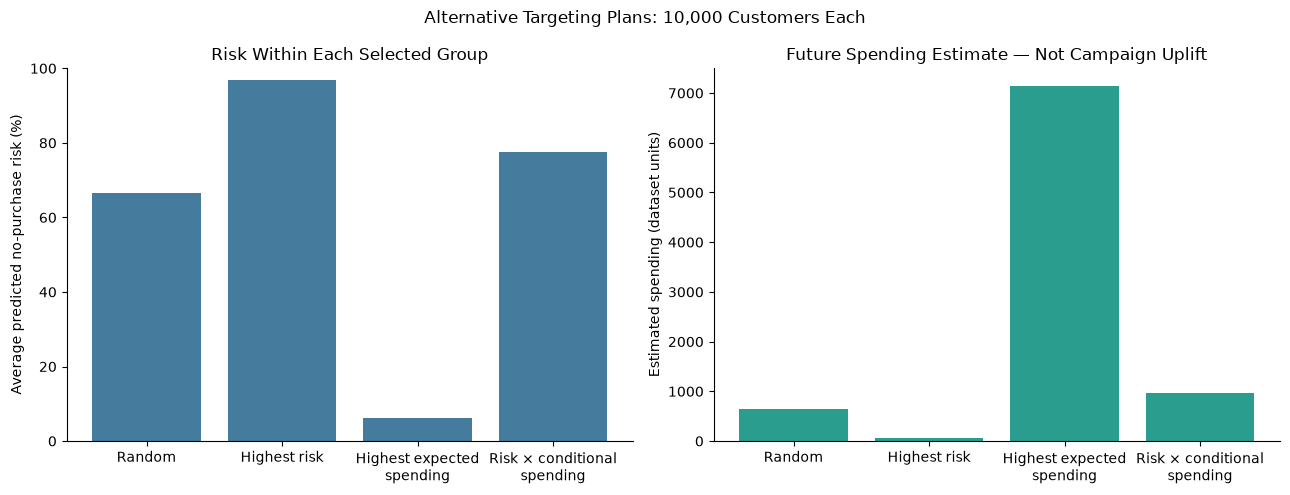

Each strategy selects 10,000 customers (0.84% of the population).


In [2]:
# 1. Validate scores before ranking customers.
probability_columns = [
    "predicted_no_purchase_probability",
    "spending_model_purchase_probability",
]
spending_columns = [
    "predicted_spend_if_purchase",
    "estimated_future_spending",
]

validation_queries = []

for column in probability_columns + spending_columns:
    invalid_condition = (
        f"{column} IS NULL OR NOT ISFINITE({column}) OR {column} < 0"
    )
    if column in probability_columns:
        invalid_condition += f" OR {column} > 1"

    validation_queries.append(f"""
        SELECT
            '{column}' AS score_field,
            COUNT(*) FILTER (
                WHERE {invalid_condition}
            ) AS invalid_values,
            MIN({column}) AS minimum,
            MAX({column}) AS maximum
        FROM campaign_scores
    """)

campaign_score_validation = campaign_con.execute(
    " UNION ALL ".join(validation_queries)
).df()

display(campaign_score_validation)
assert campaign_score_validation["invalid_values"].eq(0).all()

# Confirm a single intended scoring date and horizon.
campaign_date_check = campaign_con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE score_as_of_date IS NULL
               OR CAST(score_as_of_date AS DATE) != DATE '2020-03-31'
               OR prediction_horizon_days IS NULL
               OR prediction_horizon_days != 90
        ) AS invalid_date_or_horizon,
        MIN(score_as_of_date) AS scoring_date,
        MIN(prediction_horizon_days) AS horizon_days
    FROM campaign_scores
""").df()

display(campaign_date_check)
assert int(campaign_date_check.loc[0, "invalid_date_or_horizon"]) == 0

# 2. Create the common targeting population.
campaign_con.execute("""
    CREATE OR REPLACE TEMP VIEW campaign_targeting_population AS
    SELECT
        customer_id,
        predicted_no_purchase_probability AS no_purchase_risk,
        predicted_spend_if_purchase AS conditional_spending,
        estimated_future_spending,
        predicted_no_purchase_probability * predicted_spend_if_purchase
            AS risk_value_priority
    FROM campaign_scores
""")

contact_capacity = 10_000
population_size = int(campaign_population_check.loc[0, "customers"])
assert 0 < contact_capacity <= population_size

# Deterministic ID tie-breaks make selections reproducible.
# MD5 provides pseudorandom ordering here; it is not anonymization.
strategy_orders = {
    "Random selection": "MD5('campaign_seed_42:' || customer_id), customer_id",
    "Highest risk": "no_purchase_risk DESC, customer_id",
    "Highest expected spending": "estimated_future_spending DESC, customer_id",
    "Risk × conditional spending": "risk_value_priority DESC, customer_id",
}

selection_queries = []

for strategy, ordering in strategy_orders.items():
    selection_queries.append(f"""
        SELECT '{strategy}' AS strategy, selected.*
        FROM (
            SELECT *
            FROM campaign_targeting_population
            ORDER BY {ordering}
            LIMIT {contact_capacity}
        ) AS selected
    """)

campaign_con.execute(
    "CREATE OR REPLACE TEMP TABLE campaign_selections AS "
    + " UNION ALL ".join(selection_queries)
)

# 3. Verify equal capacity and summarize the selected populations.
campaign_strategy_summary = campaign_con.execute("""
    SELECT
        strategy,
        COUNT(*) AS selected_customers,
        COUNT(DISTINCT customer_id) AS unique_selected_customers,
        100 * AVG(no_purchase_risk) AS average_no_purchase_risk_pct,
        AVG(conditional_spending) AS average_conditional_spending,
        SUM(estimated_future_spending) AS total_estimated_future_spending,
        SUM(risk_value_priority) AS total_risk_value_priority
    FROM campaign_selections
    GROUP BY strategy
""").df()

campaign_strategy_summary = (
    campaign_strategy_summary.set_index("strategy")
    .loc[list(strategy_orders)]
    .reset_index()
)

assert campaign_strategy_summary["selected_customers"].eq(contact_capacity).all()
assert campaign_strategy_summary["unique_selected_customers"].eq(
    contact_capacity
).all()

display(
    campaign_strategy_summary.style.format({
        "selected_customers": "{:,}",
        "unique_selected_customers": "{:,}",
        "average_no_purchase_risk_pct": "{:.2f}%",
        "average_conditional_spending": "{:.4f}",
        "total_estimated_future_spending": "{:,.2f}",
        "total_risk_value_priority": "{:,.2f}",
    })
)

# 4. Compare risk concentration and estimated future spending.
labels = ["Random", "Highest risk", "Highest expected\nspending", "Risk × conditional\nspending"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    labels,
    campaign_strategy_summary["average_no_purchase_risk_pct"],
    color="#457B9D"
)
axes[0].set_ylabel("Average predicted no-purchase risk (%)")
axes[0].set_ylim(0, 100)
axes[0].set_title("Risk Within Each Selected Group")

axes[1].bar(
    labels,
    campaign_strategy_summary["total_estimated_future_spending"],
    color="#2A9D8F"
)
axes[1].set_ylabel("Estimated spending (dataset units)")
axes[1].set_title("Future Spending Estimate — Not Campaign Uplift")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"Alternative Targeting Plans: {contact_capacity:,} Customers Each")
fig.tight_layout()

fig.savefig(
    campaign_report_dir / "equal_capacity_targeting_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

campaign_strategy_summary.to_csv(
    campaign_report_dir / "equal_capacity_targeting_summary.csv",
    index=False
)

print(
    f"Each strategy selects {contact_capacity:,} customers "
    f"({100 * contact_capacity / population_size:.2f}% of the population)."
)

## 2. Hypothetical Incremental-Purchase Scenarios

Let:
- p be predicted no-purchase risk.
- s be predicted spending conditional on a purchase.
- r be an assumed fraction of otherwise non-purchasers converted by the campaign.

Scenario calculations:
- Incremental purchasers = r × sum(p)
- Incremental spending = r × sum(p × s)

Evaluate assumed conversion fractions of 0%, 1%, 3%, 5%, and 10%.

These calculations assume:
- The same conversion fraction across selected customers and strategies.
- Predicted risk approximates no-campaign non-purchase probability.
- Newly induced purchasers spend the modeled conditional amount.
- No effects on customers who would already purchase.
- No displacement of purchases from other periods.

These assumptions are not established by the dataset.
The conditional spending estimate is an imperfect proxy, and the spending
model underestimated aggregate spending in temporal evaluation.

The combined targeting rule maximizes sum(p × s) by construction.
Its advantage under this scenario is not independent evidence that it is
the most effective real campaign strategy.

Costs and margins are not included, so results are not profit or ROI estimates.

,strategy,selected_customers,assumed_conversion_fraction_pct,scenario_incremental_purchasers,scenario_incremental_spending
0,Random selection,"10,000",5%,332.3,43.27
1,Highest risk,"10,000",5%,484.7,54.62
2,Highest expected spending,"10,000",5%,31.4,22.92
3,Risk × conditional spending,"10,000",5%,388.1,133.05


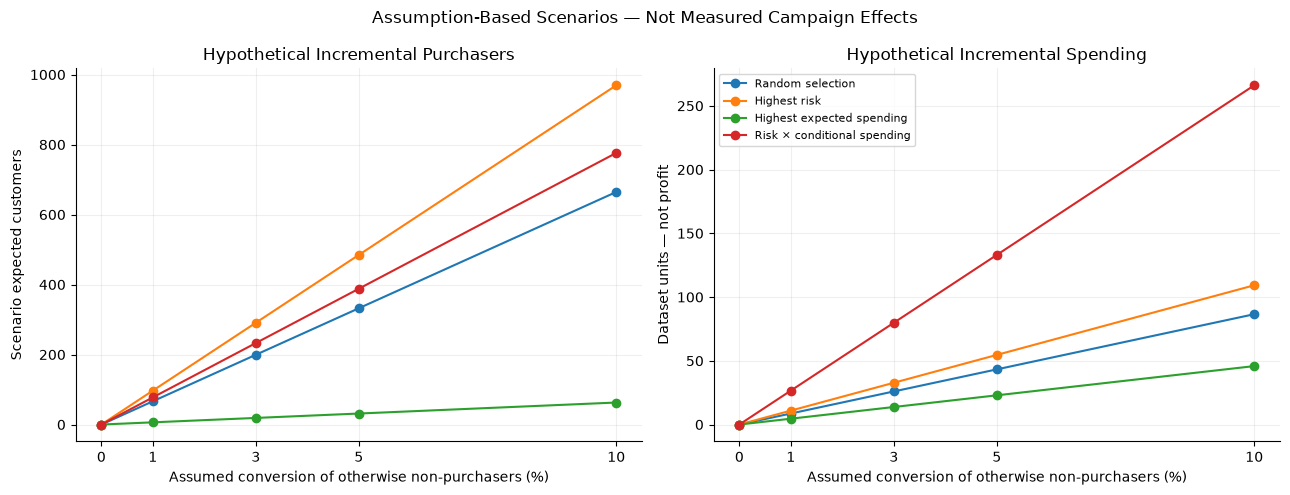

Scenario results saved.
Fractional customer counts represent expected values, not observed people.


In [3]:
# Recalculate exact totals directly from the selected customer records.
campaign_scenario_inputs = campaign_con.execute("""
    SELECT
        strategy,
        COUNT(*) AS selected_customers,
        SUM(no_purchase_risk) AS summed_no_purchase_risk,
        SUM(risk_value_priority) AS summed_risk_value_priority
    FROM campaign_selections
    GROUP BY strategy
""").df()

assumed_conversion_fractions = [0.00, 0.01, 0.03, 0.05, 0.10]

scenario_rows = []

for row in campaign_scenario_inputs.itertuples(index=False):
    for rate in assumed_conversion_fractions:
        scenario_rows.append({
            "strategy": row.strategy,
            "selected_customers": row.selected_customers,
            "assumed_conversion_fraction_pct": rate * 100,
            "scenario_incremental_purchasers": (
                rate * row.summed_no_purchase_risk
            ),
            "scenario_incremental_spending": (
                rate * row.summed_risk_value_priority
            ),
        })

campaign_scenario_results = pd.DataFrame(scenario_rows)

# Show the 5% assumption as one illustrative scenario.
example_scenario = (
    campaign_scenario_results.loc[
        campaign_scenario_results["assumed_conversion_fraction_pct"] == 5
    ]
    .set_index("strategy")
    .loc[list(strategy_orders)]
    .reset_index()
)

display(
    example_scenario.style.format({
        "selected_customers": "{:,}",
        "assumed_conversion_fraction_pct": "{:.0f}%",
        "scenario_incremental_purchasers": "{:,.1f}",
        "scenario_incremental_spending": "{:,.2f}",
    })
)

# Basic scenario checks.
zero_scenario = campaign_scenario_results.loc[
    campaign_scenario_results["assumed_conversion_fraction_pct"] == 0
]

assert zero_scenario[
    ["scenario_incremental_purchasers", "scenario_incremental_spending"]
].eq(0).all().all()

assert (
    campaign_scenario_results["scenario_incremental_purchasers"]
    <= campaign_scenario_results["selected_customers"]
).all()

# Show how outcomes change with the assumed conversion fraction.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for strategy in strategy_orders:
    strategy_data = campaign_scenario_results.loc[
        campaign_scenario_results["strategy"] == strategy
    ].sort_values("assumed_conversion_fraction_pct")

    axes[0].plot(
        strategy_data["assumed_conversion_fraction_pct"],
        strategy_data["scenario_incremental_purchasers"],
        marker="o",
        label=strategy
    )

    axes[1].plot(
        strategy_data["assumed_conversion_fraction_pct"],
        strategy_data["scenario_incremental_spending"],
        marker="o",
        label=strategy
    )

axes[0].set_title("Hypothetical Incremental Purchasers")
axes[0].set_ylabel("Scenario expected customers")

axes[1].set_title("Hypothetical Incremental Spending")
axes[1].set_ylabel("Dataset units — not profit")

for ax in axes:
    ax.set_xlabel("Assumed conversion of otherwise non-purchasers (%)")
    ax.set_xticks([0, 1, 3, 5, 10])
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[1].legend(fontsize=8)
fig.suptitle("Assumption-Based Scenarios — Not Measured Campaign Effects")
fig.tight_layout()

fig.savefig(
    campaign_report_dir / "hypothetical_campaign_conversion_scenarios.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

campaign_scenario_results.to_csv(
    campaign_report_dir / "hypothetical_campaign_conversion_scenarios.csv",
    index=False
)

print("Scenario results saved.")
print("Fractional customer counts represent expected values, not observed people.")

### Scenario Findings

Under an assumed 5% conversion of otherwise non-purchasers, highest-risk
targeting produces the largest expected number of incremental purchasers
(484.7), while combined risk-and-value targeting produces the largest
hypothetical incremental spending (133.05 dataset units).

Highest-expected-spending targeting produces fewer incremental purchasers
under this assumption because its selected customers have low predicted
no-purchase risk.

These are assumption-driven calculations, not measured campaign outcomes.
The combined rule maximizes the scenario's spending formula by construction.
Actual strategy performance requires campaign treatment and control data.

## 3. Hypothetical Break-Even Campaign Cost

Apply illustrative contribution margins of 20%, 40%, and 60% to scenario
incremental spending.

Break-even total campaign cost = incremental spending × contribution margin.

Break-even cost per contacted customer = break-even total cost / contacts.

The assumed margin represents the share of incremental spending remaining
after variable product costs but before campaign-specific costs.

All campaign-specific costs must fit within this allowance, including
contact costs, incentives, and any allocated fixed campaign costs.

These are hypothetical cost ceilings in dataset units, not actual budgets,
verified profit estimates, or currency amounts.

,strategy,selected_customers,break_even_total_campaign_cost,break_even_cost_per_contact
0,Random selection,"10,000",17.3086,0.001731
1,Highest risk,"10,000",21.8481,0.002185
2,Highest expected spending,"10,000",9.1668,0.000917
3,Risk × conditional spending,"10,000",53.2195,0.005322


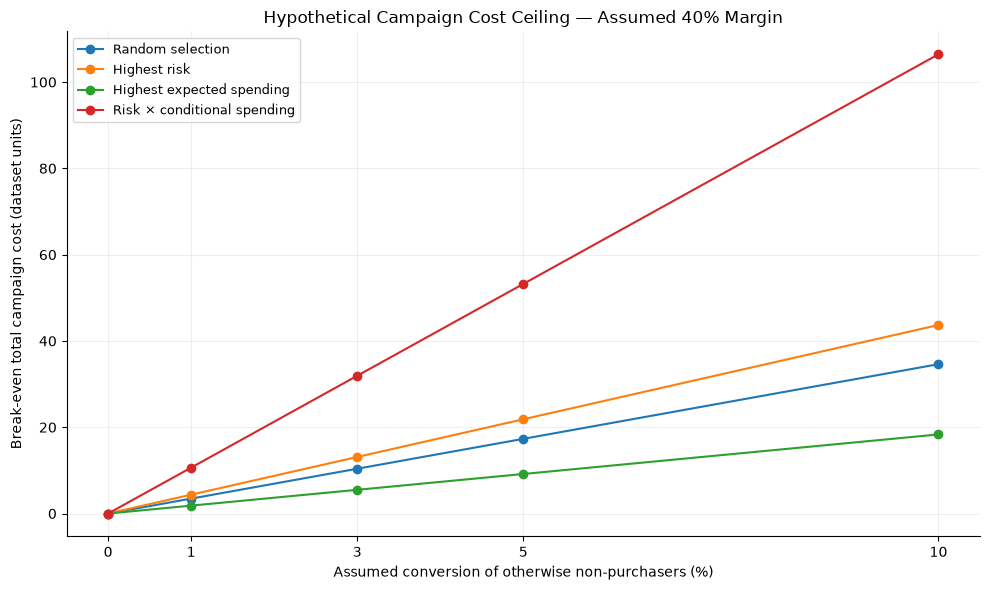

Break-even scenarios saved. All amounts are in dataset units.


In [4]:
assumed_margin_fractions = [0.20, 0.40, 0.60]

break_even_rows = []

for row in campaign_scenario_results.itertuples(index=False):
    for margin in assumed_margin_fractions:
        cost_allowance = row.scenario_incremental_spending * margin

        break_even_rows.append({
            "strategy": row.strategy,
            "selected_customers": row.selected_customers,
            "assumed_conversion_fraction_pct":
                row.assumed_conversion_fraction_pct,
            "assumed_margin_pct": margin * 100,
            "scenario_incremental_spending":
                row.scenario_incremental_spending,
            "break_even_total_campaign_cost": cost_allowance,
            "break_even_cost_per_contact":
                cost_allowance / row.selected_customers,
        })

campaign_break_even_results = pd.DataFrame(break_even_rows)

# Illustrative example: 5% conversion and 40% contribution margin.
break_even_example = (
    campaign_break_even_results.loc[
        (campaign_break_even_results["assumed_conversion_fraction_pct"] == 5)
        & (campaign_break_even_results["assumed_margin_pct"] == 40)
    ]
    .set_index("strategy")
    .loc[list(strategy_orders)]
    .reset_index()
)

display(
    break_even_example[
        [
            "strategy",
            "selected_customers",
            "break_even_total_campaign_cost",
            "break_even_cost_per_contact",
        ]
    ].style.format({
        "selected_customers": "{:,}",
        "break_even_total_campaign_cost": "{:.4f}",
        "break_even_cost_per_contact": "{:.6f}",
    })
)

# Sensitivity to assumed conversion, holding margin at 40%.
fig, ax = plt.subplots(figsize=(10, 6))

for strategy in strategy_orders:
    plot_data = campaign_break_even_results.loc[
        (campaign_break_even_results["strategy"] == strategy)
        & (campaign_break_even_results["assumed_margin_pct"] == 40)
    ].sort_values("assumed_conversion_fraction_pct")

    ax.plot(
        plot_data["assumed_conversion_fraction_pct"],
        plot_data["break_even_total_campaign_cost"],
        marker="o",
        label=strategy
    )

ax.set_title("Hypothetical Campaign Cost Ceiling — Assumed 40% Margin")
ax.set_xlabel("Assumed conversion of otherwise non-purchasers (%)")
ax.set_ylabel("Break-even total campaign cost (dataset units)")
ax.set_xticks([0, 1, 3, 5, 10])
ax.grid(alpha=0.2)
ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(
    campaign_report_dir / "hypothetical_break_even_campaign_cost.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

campaign_break_even_results.to_csv(
    campaign_report_dir / "hypothetical_break_even_campaign_cost.csv",
    index=False
)

print("Break-even scenarios saved. All amounts are in dataset units.")

## 4. Campaign Simulator Conclusion

Four targeting strategies were compared at an equal capacity of 10,000 customers.

Under the illustrative assumptions of 5% conversion of otherwise non-purchasers
and a 40% contribution margin, combined risk-and-value targeting produced
the highest hypothetical campaign cost ceiling: 53.2195 dataset units.

This result follows from the scenario formula and targeting rule.
It does not demonstrate superior real-world campaign effectiveness.

The simulator supports assumption-based planning. Measuring incremental
purchases, spending, and profitability requires treatment and control data.

Selections, scenario inputs, formulas, and assumptions are saved for
reproducibility and dashboard integration.


In [5]:
import json
from datetime import datetime, timezone

campaign_artifact_dir = project_root / "models" / "campaign_simulator"
campaign_artifact_dir.mkdir(parents=True, exist_ok=True)

# 1. Save the selected customer records for all four alternative strategies.
selection_path = campaign_artifact_dir / "campaign_selections.parquet"
sql_path = selection_path.as_posix().replace("'", "''")

campaign_con.execute(f"""
    COPY (
        SELECT *
        FROM campaign_selections
        ORDER BY strategy, customer_id
    )
    TO '{sql_path}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

# 2. Save exact aggregate inputs and scenario outputs.
campaign_scenario_inputs.to_csv(
    campaign_artifact_dir / "scenario_inputs.csv",
    index=False
)
campaign_strategy_summary.to_csv(
    campaign_artifact_dir / "targeting_summary.csv",
    index=False
)
campaign_scenario_results.to_csv(
    campaign_artifact_dir / "conversion_scenarios.csv",
    index=False
)
campaign_break_even_results.to_csv(
    campaign_artifact_dir / "break_even_scenarios.csv",
    index=False
)

# 3. Record rules and assumptions.
campaign_metadata = {
    "artifact_type": "Assumption-based campaign simulator",
    "score_source": str(campaign_scores_path.relative_to(project_root)),
    "score_as_of_date": "2020-03-31",
    "prediction_horizon_days": 90,
    "population_customers": population_size,
    "contact_capacity_per_strategy": contact_capacity,
    "strategy_ordering_sql": strategy_orders,
    "random_selection_seed_label": "campaign_seed_42",
    "conversion_fractions": assumed_conversion_fractions,
    "margin_fractions": assumed_margin_fractions,
    "monetary_units": "Dataset units; no currency conversion established",
    "formulas": {
        "incremental_purchasers": "r * sum(no_purchase_risk)",
        "incremental_spending": "r * sum(no_purchase_risk * conditional_spending)",
        "break_even_total_campaign_cost": "incremental_spending * margin",
        "break_even_cost_per_contact": "break_even_total_campaign_cost / contacts"
    },
    "assumptions": [
        "r is conversion among customers who otherwise would not purchase.",
        "Conversion fraction is uniform across customers and strategies.",
        "Risk scores approximate no-campaign non-purchase probabilities.",
        "Induced purchasers spend the modeled conditional amount.",
        "No effect on customers who would purchase anyway.",
        "No displacement of purchases across periods.",
        "All campaign-specific costs must fit within the cost ceiling."
    ],
    "limitations": [
        "No campaign treatment/control outcomes are available.",
        "Results are scenarios, not measured causal effects.",
        "Combined targeting maximizes the scenario spending formula by construction.",
        "Spending estimates inherit the saved model's temporal underestimation.",
        "Strategies overlap and are alternative plans, not experimental arms.",
        "Saved selections cover the fixed contact capacity only."
    ],
    "created_at_utc": datetime.now(timezone.utc).isoformat()
}

(campaign_artifact_dir / "metadata.json").write_text(
    json.dumps(campaign_metadata, indent=2, allow_nan=False),
    encoding="utf-8"
)

# 4. Reload saved selections and verify group counts and aggregate inputs.
with duckdb.connect() as verification_con:
    saved_selection_summary = verification_con.execute("""
        SELECT
            strategy,
            COUNT(*) AS selected_customers,
            COUNT(DISTINCT customer_id) AS unique_customers,
            SUM(no_purchase_risk) AS summed_no_purchase_risk,
            SUM(risk_value_priority) AS summed_risk_value_priority
        FROM read_parquet(?)
        GROUP BY strategy
        ORDER BY strategy
    """, [str(selection_path)]).df()

saved_inputs = pd.read_csv(campaign_artifact_dir / "scenario_inputs.csv")

assert set(saved_selection_summary["strategy"]) == set(saved_inputs["strategy"])
assert saved_selection_summary["selected_customers"].eq(contact_capacity).all()
assert saved_selection_summary["unique_customers"].eq(contact_capacity).all()

check = saved_selection_summary.merge(
    saved_inputs,
    on="strategy",
    suffixes=("_reloaded", "_saved"),
    validate="one_to_one"
)

for column in [
    "summed_no_purchase_risk",
    "summed_risk_value_priority"
]:
    np.testing.assert_allclose(
        check[f"{column}_reloaded"],
        check[f"{column}_saved"],
        rtol=1e-10,
        atol=1e-8
    )

display(
    saved_selection_summary[
        ["strategy", "selected_customers", "unique_customers"]
    ]
)

print("PASS: saved selections reproduce the scenario aggregate inputs.")
print("Saved simulator artifacts:", campaign_artifact_dir)
print("Total saved selection rows:", int(
    saved_selection_summary["selected_customers"].sum()
))

,strategy,selected_customers,unique_customers
0,Highest expected spending,10000,10000
1,Highest risk,10000,10000
2,Random selection,10000,10000
3,Risk × conditional spending,10000,10000


PASS: saved selections reproduce the scenario aggregate inputs.
Saved simulator artifacts: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\models\campaign_simulator
Total saved selection rows: 40000


In [6]:
import sys
from importlib import util, metadata

print("Python:", sys.executable)

for package in ["streamlit", "plotly", "duckdb", "pandas", "catboost"]:
    if util.find_spec(package) is None:
        print(f"{package}: NOT INSTALLED")
    else:
        print(f"{package}: {metadata.version(package)}")

Python: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\.venv\Scripts\python.exe
streamlit: NOT INSTALLED
plotly: 7.1.0
duckdb: 1.5.5
pandas: 3.0.6
catboost: 1.2.10


In [7]:
%pip install --only-binary=:all: streamlit==1.64.0

  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached pyarrow-25.0.1-cp314-cp314-win_amd64.whl.metadata (3.0 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached toml-0.10.2-py2.py3-none-any.whl.metadata (7.1 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached python_multipart-0.0.32-py3-none-any.whl.metadata (2.1 kB)
  Using cached websockets-16.1.1-cp314-cp314-win_amd64.whl.metadata (7.0 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached watchdog-6.0.0-py3-none-win_amd64.whl.metadata (44 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached idna-3.20-py3-none-any.wh